<a href="https://colab.research.google.com/github/Rahardirizky/modul-soil-improvement/blob/main/modul_M2_PVD_Hansbo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL 2 — PVD DESIGN USING HANSBO'S RADIAL CONSOLIDATION THEORY

**Tujuan:** menentukan jarak Prefabricated Vertical Drain (PVD) untuk target konsolidasi dan waktu desain, serta membuat kurva derajat konsolidasi terhadap waktu.

**Sumber utama:** materi dosen *MPT_Minggu3_PVD_EN_rev2*, Bagian 3.4 dan 3.6. Rujukan teori yang disebut di dalamnya: Terzaghi, Carrillo (1942), Hansbo (1981), PD T-13-2004-A, dan FHWA GEC No. 13 (2016).

Ruang lingkup dibuat sederhana: Terzaghi untuk kontribusi vertikal, Carrillo untuk menggabungkan vertikal dan radial, serta Hansbo untuk desain radial PVD. Modul ini tidak menghitung settlement akhir (ranah M1), stabilitas timbunan, atau tahapan konstruksi.


## 1. Teori dan alur perhitungan

### 1.1 Terzaghi — konsolidasi vertikal
\[
T_v=\frac{c_vt}{H_{dr}^2}
\]
\(c_v\): koefisien konsolidasi vertikal (m²/hari); \(t\): waktu (hari); \(H_{dr}\): panjang lintasan drainase vertikal (m). Single drainage: \(H_{dr}=H\); double drainage: \(H_{dr}=H/2\). Nilai \(U_v\) diperoleh dari tabel \(U_v-T_v\) materi dosen halaman tercetak 32; notebook menginterpolasi linear antar titik tabel.

### 1.2 Carrillo — kombinasi vertikal dan radial
\[
\bar U=1-(1-\bar U_v)(1-\bar U_h)
\]
\[
\boxed{\bar U_h=1-\frac{1-\bar U}{1-\bar U_v}}
\]
Semua U dalam fungsi menggunakan desimal 0–1, bukan persen.

### 1.3 Geometri PVD dan unit cell
Untuk PVD berbentuk pita, lebar \(a\), tebal \(b\):
\[
d_w=\frac{2(a+b)}{\pi}
\]
Diameter ekuivalen mandrel dari luas penampang \(A_m\):
\[
d_m=\sqrt{\frac{4A_m}{\pi}},\qquad d_s=2.5d_m
\]
Pendekatan \(d_s=2.5d_m\) mengikuti worked example materi dosen.
\[
D=1.05s\quad(\text{segitiga}),\qquad D=1.13s\quad(\text{bujur sangkar})
\]

### 1.4 Hansbo (1981) — konsolidasi radial
\[
t=\frac{D^2}{8c_h}[F(n)+F_s+F_r]\ln\left(\frac{1}{1-\bar U_h}\right)
\]
\[
F(n)=\ln(D/d_w)-0.75
\]
\[
F_s=(k_h/k_s-1)\ln(d_s/d_w)
\]
Materi dosen halaman 33 menampilkan \(F_r(z)=\pi z(L-z)k_h/q_w\). Untuk worked example, halaman 57–58 menggunakan bentuk rata-rata:
\[
\boxed{F_r=\frac{\pi L^2k_h}{6q_w}}
\]
Notebook menggunakan bentuk rata-rata tersebut. Satuan yang dipakai: panjang m, \(c_h\) m²/hari, \(k_h,k_s\) m/hari, \(q_w\) m³/hari. Dengan demikian \(F_r\) tidak berdimensi.

### 1.5 Alur desain
1. Hitung \(T_v\) dan \(U_v\) pada waktu desain.
2. Hitung target radial \(U_h\) menggunakan Carrillo.
3. Hitung \(d_w,d_m,d_s\).
4. Trial spacing \(s\): hitung \(D,F(n),F_s,F_r\), lalu waktu Hansbo.
5. Cari spacing terbesar yang masih memenuhi waktu desain, untuk pola segitiga dan bujur sangkar.
6. Buat kurva \(U_v(t),U_h(t),U(t)\).

**Interpretasi:** PVD mempercepat laju konsolidasi, bukan otomatis mengurangi settlement primer akhir. Settlement akhir dihitung terpisah, misalnya di M1.


## 2. Peta keterlacakan sumber

| Topik | Materi dosen (nomor halaman tercetak) |
|---|---:|
| Terzaghi, \(T_v\) dan tabel \(U_v-T_v\) | 32 |
| Persamaan Hansbo, \(F(n),F_s,F_r(z)\) | 33 |
| Carrillo | 36 |
| Diameter ekuivalen PVD | 37 |
| Pola dan diameter pengaruh \(D\) | 38 |
| Smear zone dan mandrel | 39 |
| Worked example Hansbo | 56–58 |

**Catatan:** hasil worked example tercantum di materi kelas \(s=2.40\) m (segitiga), \(D=2.52\) m, μ=4.18, \(t=686\) hari. Namun, seluruh data independen untuk \(k_h,q_w,L\) dan satuannya harus ditelusuri sebelum angka tersebut dijadikan unit test numerik. Karena itu, angka benchmark dicatat sebagai referensi manual, bukan dipaksakan menjadi test kode.


## 3. Imports

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt


## 4. Main functions

### Function 1 — Vertical consolidation (Terzaghi)
Tabel \(U_v-T_v\) diambil dari materi dosen halaman tercetak 32. Interpolasi linear digunakan di antara titik tabel; ekstrapolasi di luar rentang ditolak.

In [2]:
def calculate_vertical_consolidation(cv, time, drainage_path):
    """Return Tv and Uv (decimal) using lecture Uv-Tv table. Units: m2/day, day, m."""
    if not all(math.isfinite(float(x)) for x in [cv, time, drainage_path]):
        raise ValueError("Inputs must be finite.")
    if cv <= 0 or time < 0 or drainage_path <= 0:
        raise ValueError("cv and drainage_path must be > 0; time must be >= 0.")

    tv = cv * time / drainage_path**2
    tv_points = [0.0, 0.008, 0.031, 0.071, 0.126, 0.197, 0.287, 0.405, 0.567, 0.848, 1.127]
    uv_points = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    if not tv_points[0] <= tv <= tv_points[-1]:
        raise ValueError(f"Tv={tv:.4f} outside lecture table range {tv_points[0]}–{tv_points[-1]}.")
    uv = float(pd.Series(uv_points, index=tv_points).reindex(
        sorted(set(tv_points + [tv]))
    ).interpolate(method="index").loc[tv])
    return {"Tv": tv, "Uv": uv}


### Function 2 — Carrillo combination and required radial consolidation

In [4]:
def combine_consolidation(uv, uh):
    """Total average consolidation using Carrillo; U values are decimals."""
    if not (0 <= uv <= 1 and 0 <= uh <= 1):
        raise ValueError("uv and uh must be between 0 and 1.")
    return 1 - (1 - uv) * (1 - uh)


def calculate_required_radial_consolidation(target_u, uv):
    """Required Uh to achieve target total U, given vertical Uv."""
    if not 0 < target_u < 1 or not 0 <= uv < 1:
        raise ValueError("target_u must be (0,1); uv must be [0,1).")
    uh = 1 - (1 - target_u) / (1 - uv)
    if not 0 <= uh < 1:
        raise ValueError("Vertical consolidation is already at/above target or inputs are incompatible.")
    return uh


### Function 3 — Equivalent PVD, mandrel, and smear geometry
Dimensi PVD dan mandrel dimasukkan dalam meter.

In [5]:
def calculate_drain_geometry(drain_width, drain_thickness, mandrel_area, smear_ratio=2.5):
    """Return dw, dm, ds in metres. ds/dm default follows lecture worked example."""
    vals = [drain_width, drain_thickness, mandrel_area, smear_ratio]
    if not all(math.isfinite(float(x)) for x in vals) or min(vals) <= 0:
        raise ValueError("All geometry inputs must be finite and > 0.")
    dw = 2 * (drain_width + drain_thickness) / math.pi
    dm = math.sqrt(4 * mandrel_area / math.pi)
    ds = smear_ratio * dm
    if ds <= dw:
        raise ValueError("ds must be greater than dw.")
    return {"dw_m": dw, "dm_m": dm, "ds_m": ds}


### Function 4 — Hansbo resistance factors
Menggunakan bentuk rata-rata \(F_r\) pada worked example materi dosen. \(k_h,k_s\) dalam m/hari dan \(q_w\) dalam m³/hari.

In [6]:
def calculate_hansbo_factors(D, dw, ds, kh, ks, drain_length, qw):
    """Return Fn, Fs, average Fr and mu. Lengths in m, k in m/day, qw in m3/day."""
    vals = [D, dw, ds, kh, ks, drain_length, qw]
    if not all(math.isfinite(float(x)) for x in vals):
        raise ValueError("Inputs must be finite.")
    if min(D, dw, kh, ks, drain_length, qw) <= 0 or ds <= dw or D <= dw:
        raise ValueError("Check positive values and require D > dw and ds > dw.")
    fn = math.log(D / dw) - 0.75
    fs = (kh / ks - 1) * math.log(ds / dw)
    fr = math.pi * drain_length**2 * kh / (6 * qw)
    mu = fn + fs + fr
    if min(fn, fs, fr) < 0 or mu <= 0:
        raise ValueError("Non-positive resistance factor; review assumptions.")
    return {"Fn": fn, "Fs": fs, "Fr": fr, "mu": mu}


### Function 5 — Hansbo time and radial consolidation
Persamaan yang sama digunakan dalam dua arah: target \(U_h\) menjadi waktu, atau waktu menjadi \(U_h\).

In [7]:
def calculate_hansbo_time(D, ch, uh, mu):
    """Required time (day) from Hansbo. ch in m2/day."""
    if D <= 0 or ch <= 0 or mu <= 0 or not 0 < uh < 1:
        raise ValueError("Require D,ch,mu > 0 and 0 < uh < 1.")
    return D**2 / (8 * ch) * mu * math.log(1 / (1 - uh))


def calculate_radial_consolidation(D, ch, time, mu):
    """Average radial degree Uh (decimal) at elapsed time (day)."""
    if D <= 0 or ch <= 0 or time < 0 or mu <= 0:
        raise ValueError("Require D,ch,mu > 0 and time >= 0.")
    return 1 - math.exp(-8 * ch * time / (D**2 * mu))


### Function 6 — Evaluate trial spacing and find design spacing
Bisection mencari spacing terbesar yang masih memenuhi waktu desain. Batas bawah harus feasible dan batas atas harus tidak feasible.

In [8]:
def evaluate_spacing(spacing, pattern, dw, ds, kh, ks, ch, drain_length, qw, uh_target):
    """Calculate D, Hansbo factors and time for one spacing trial."""
    factors_by_pattern = {"triangular": 1.05, "square": 1.13}
    if pattern not in factors_by_pattern or spacing <= 0:
        raise ValueError("Use positive spacing and pattern 'triangular' or 'square'.")
    D = factors_by_pattern[pattern] * spacing
    factors = calculate_hansbo_factors(D, dw, ds, kh, ks, drain_length, qw)
    t = calculate_hansbo_time(D, ch, uh_target, factors["mu"])
    return {"pattern": pattern, "spacing_m": spacing, "D_m": D,
            **factors, "time_days": t}


def calculate_required_spacing(pattern, available_time, uh_target, dw, ds, kh, ks,
                               ch, drain_length, qw, lower_spacing=0.2,
                               upper_spacing=5.0, tolerance=1e-4, max_iterations=200):
    """Largest feasible spacing by bisection; all time values in days."""
    if available_time <= 0 or lower_spacing <= 0 or upper_spacing <= lower_spacing:
        raise ValueError("Invalid time or spacing bounds.")
    low = evaluate_spacing(lower_spacing, pattern, dw, ds, kh, ks, ch, drain_length, qw, uh_target)
    high = evaluate_spacing(upper_spacing, pattern, dw, ds, kh, ks, ch, drain_length, qw, uh_target)
    if low["time_days"] > available_time:
        raise ValueError("Lower spacing is not feasible; reduce lower_spacing.")
    if high["time_days"] <= available_time:
        raise ValueError("Upper spacing is feasible; increase upper_spacing.")
    for _ in range(max_iterations):
        mid = (lower_spacing + upper_spacing) / 2
        result = evaluate_spacing(mid, pattern, dw, ds, kh, ks, ch, drain_length, qw, uh_target)
        if result["time_days"] <= available_time:
            lower_spacing = mid
        else:
            upper_spacing = mid
        if upper_spacing - lower_spacing <= tolerance:
            break
    return evaluate_spacing(lower_spacing, pattern, dw, ds, kh, ks, ch, drain_length, qw, uh_target)


## 5. Integrated M2 workflow

In [9]:
def calculate_m2_pvd(cv, ch, drainage_path, design_time, target_u,
                     drain_width, drain_thickness, mandrel_area,
                     kh, ks, drain_length, qw, spacing_bounds=(0.2, 5.0)):
    """Integrated design: Terzaghi -> Carrillo -> geometry -> Hansbo spacing."""
    vertical = calculate_vertical_consolidation(cv, design_time, drainage_path)
    uh = calculate_required_radial_consolidation(target_u, vertical["Uv"])
    geometry = calculate_drain_geometry(drain_width, drain_thickness, mandrel_area)
    lo, hi = spacing_bounds
    results = []
    for pattern in ["triangular", "square"]:
        results.append(calculate_required_spacing(
            pattern, design_time, uh, geometry["dw_m"], geometry["ds_m"],
            kh, ks, ch, drain_length, qw, lo, hi
        ))
    return {"vertical": vertical, "target_total_U": target_u,
            "required_radial_U": uh, "geometry": geometry,
            "spacing_results": pd.DataFrame(results)}


## 6. Demonstration

**Seluruh input di bawah bersifat ilustratif**, bukan data proyek atau reproduksi lengkap worked example dosen. Khusus \(k_h\) dan \(k_s\), ganti dengan data yang memiliki dasar pengujian atau asumsi desain yang dinyatakan.


In [10]:
demo = calculate_m2_pvd(
    cv=0.00929, ch=0.00929,       # m2/day; illustrative ch=cv
    drainage_path=9.0,            # m; double drainage for 18 m clay
    design_time=730.0, target_u=0.90,
    drain_width=0.100, drain_thickness=0.004,  # m
    mandrel_area=0.0072,          # m2
    kh=0.10, ks=0.05,             # m/day; illustrative, kh/ks=2
    drain_length=18.0,            # m
    qw=1200.0/365.0               # m3/day; 1,200 m3/year
)
print("Vertical:", demo["vertical"])
print("Required radial U:", round(demo["required_radial_U"], 4))
print("Geometry:", demo["geometry"])
display(demo["spacing_results"].round(4))


Vertical: {'Tv': 0.08372469135802468, 'Uv': 0.3231358024691358}
Required radial U: 0.8523
Geometry: {'dw_m': 0.06620845632622847, 'dm_m': 0.09574614729634384, 'ds_m': 0.2393653682408596}


,pattern,spacing_m,D_m,Fn,Fs,Fr,mu,time_days
0,triangular,1.6923,1.7769,2.5398,1.2852,5.1601,8.9851,729.9794
1,square,1.5725,1.7769,2.5398,1.2852,5.1601,8.9851,729.9650


## 7. Consolidation curve
Kurva menggunakan interpolasi tabel Terzaghi untuk \(U_v(t)\), Hansbo untuk \(U_h(t)\), dan Carrillo untuk \(U(t)\).

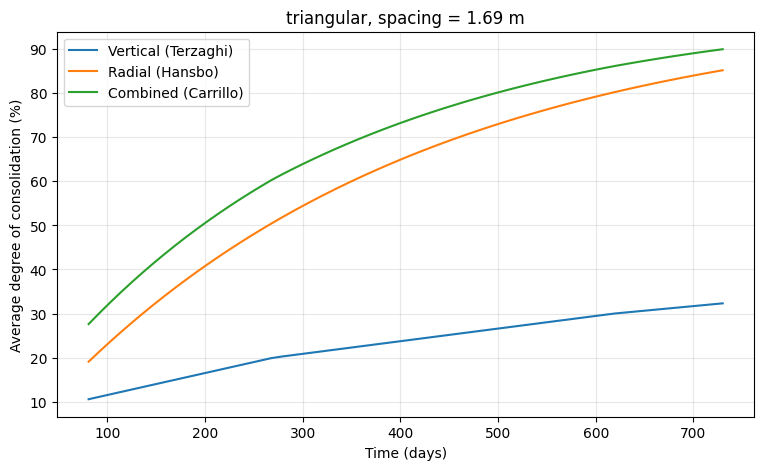

,time_days,Uv,Uh,U_total
55,685.9835,0.3140,0.8342,0.8863
56,696.9876,0.3163,0.8389,0.8899
57,707.9917,0.3185,0.8435,0.8934
58,718.9959,0.3208,0.8479,0.8967
59,730.0000,0.3231,0.8523,0.9000


In [11]:
def plot_consolidation_curve(cv, ch, drainage_path, spacing_result,
                             geometry, kh, ks, drain_length, qw,
                             max_time, number_of_points=60):
    """Plot Uv, Uh and combined U versus time. max_time in days."""
    if max_time <= 0 or number_of_points < 2:
        raise ValueError("max_time > 0 and number_of_points >= 2 required.")
    D = spacing_result["D_m"]
    f = calculate_hansbo_factors(D, geometry["dw_m"], geometry["ds_m"],
                                 kh, ks, drain_length, qw)
    rows = []
    t_min = 0.008 * drainage_path**2 / cv
    for i in range(1, number_of_points + 1):
        t = t_min + (max_time - t_min) * i / number_of_points
        uv = calculate_vertical_consolidation(cv, t, drainage_path)["Uv"]
        uh = calculate_radial_consolidation(D, ch, t, f["mu"])
        rows.append({"time_days": t, "Uv": uv, "Uh": uh,
                     "U_total": combine_consolidation(uv, uh)})
    curve = pd.DataFrame(rows)
    plt.figure(figsize=(9, 5))
    plt.plot(curve.time_days, curve.Uv * 100, label="Vertical (Terzaghi)")
    plt.plot(curve.time_days, curve.Uh * 100, label="Radial (Hansbo)")
    plt.plot(curve.time_days, curve.U_total * 100, label="Combined (Carrillo)")
    plt.xlabel("Time (days)")
    plt.ylabel("Average degree of consolidation (%)")
    plt.title(f'{spacing_result["pattern"]}, spacing = {spacing_result["spacing_m"]:.2f} m')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
    return curve


chosen = demo["spacing_results"].iloc[0].to_dict()
curve = plot_consolidation_curve(
    cv=0.00929, ch=0.00929, drainage_path=9.0,
    spacing_result=chosen, geometry=demo["geometry"],
    kh=0.10, ks=0.05, drain_length=18.0, qw=1200.0/365.0,
    max_time=730.0
)
display(curve.tail().round(4))


## 8. Unit tests

Test menguji setiap bagian secara terpisah dan integrasi persamaan. Toleransi numerik ketat digunakan untuk memeriksa implementasi terhadap hasil analitis, bukan sebagai toleransi validasi tugas ±2%.


In [12]:
# 1. Terzaghi: Tv = 0.848 maps to Uv = 0.90 in lecture table
v = calculate_vertical_consolidation(cv=0.848, time=100, drainage_path=10)
assert math.isclose(v["Tv"], 0.848, rel_tol=1e-10)
assert math.isclose(v["Uv"], 0.90, rel_tol=1e-10)

# 2. Carrillo combination
assert math.isclose(combine_consolidation(0.30, 0.80), 0.86, rel_tol=1e-10)

# 3. Required radial consolidation from U=0.90 and Uv=0.326
assert math.isclose(calculate_required_radial_consolidation(0.90, 0.326),
                    1 - 0.10/0.674, rel_tol=1e-10)

# 4. Equivalent drain diameter for 100 x 4 mm PVD
g = calculate_drain_geometry(0.100, 0.004, 0.0072)
assert math.isclose(g["dw_m"], 2*0.104/math.pi, rel_tol=1e-10)
assert math.isclose(g["dm_m"], math.sqrt(4*0.0072/math.pi), rel_tol=1e-10)

# 5. Hansbo factors against direct analytical expressions
f = calculate_hansbo_factors(1.575, 0.066, 0.24, 0.10, 0.05, 18, 1200/365)
assert math.isclose(f["Fn"], math.log(1.575/0.066)-0.75, rel_tol=1e-10)
assert math.isclose(f["Fs"], math.log(0.24/0.066), rel_tol=1e-10)
assert math.isclose(f["Fr"], math.pi*18**2*0.10/(6*(1200/365)), rel_tol=1e-10)

# 6. Hansbo forward and inverse calculations are consistent
t = calculate_hansbo_time(1.575, 0.00929, 0.853, f["mu"])
assert math.isclose(calculate_radial_consolidation(1.575, 0.00929, t, f["mu"]),
                    0.853, rel_tol=1e-10)

# 7. Triangular pattern conversion
trial = evaluate_spacing(1.5, "triangular", 0.066, 0.24, 0.10, 0.05,
                         0.00929, 18, 1200/365, 0.853)
assert math.isclose(trial["D_m"], 1.05*1.5, rel_tol=1e-10)
assert trial["time_days"] > 0

# 8. Invalid pattern is rejected
try:
    evaluate_spacing(1.5, "hexagonal", 0.066, 0.24, 0.10, 0.05,
                     0.00929, 18, 1200/365, 0.853)
except ValueError:
    pass
else:
    raise AssertionError("Invalid pattern should raise ValueError.")

print("All 8 M2 unit tests passed.")


All 8 M2 unit tests passed.


## 9. Validasi dan batasan

- Unit tests memeriksa implementasi fungsi; belum menggantikan validasi terhadap contoh kuliah dan soal UTS yang ditetapkan.
- Materi halaman 58 melaporkan spacing 2.40 m (segitiga), \(D=2.52\) m, μ=4.18, dan waktu 686 hari. Sebelum dijadikan validasi numerik otomatis, seluruh input yang membentuk \(F_r\) dan μ harus ditelusuri, terutama \(k_h,q_w,L\), serta satuannya.
- Demo menggunakan \(k_h,k_s\) ilustratif; hasil spacing demo bukan rekomendasi desain proyek.
- Implementasi memakai bentuk rata-rata \(F_r=πL^2k_h/(6q_w)\), sesuai worked example. Bentuk \(F_r(z)\) pada halaman 33 dijelaskan di teori tetapi tidak dihitung per kedalaman.
- Parameter dianggap homogen terhadap kedalaman. Profil berlapis dengan nilai \(c_h,k_h,k_s\) berbeda membutuhkan pengembangan model.
- Model tidak menghitung stabilitas timbunan, tahapan konstruksi, settlement akhir, atau verifikasi discharge capacity lapangan.
- Fungsi \(U_v\) menolak \(T_v\) di luar rentang tabel materi; tidak melakukan ekstrapolasi.
